#LIBRARY

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

#DATA LOADING

In [ ]:
df = pd.read_csv("/content/heart_rate_dataset.csv")

print("--------- Dataset Overview ------")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print(df.head())

print("------------ Checking The Missing Values")
print(df.isnull().sum())

--------- Dataset Overview ------
Total Rows: 200, Total Columns: 8
             Timestamp  Age  Gender  Activity  SpO2  BodyTemp  StressLevel  \
0  2024-01-01 00:00:00   60    Male   Resting  98.6      36.5            3   
1  2024-01-01 01:00:00   63    Male  Exercise  97.1      36.2            4   
2  2024-01-01 02:00:00   52    Male  Exercise  96.0      37.2            9   
3  2024-01-01 03:00:00   34  Female  Exercise  96.4      37.6            3   
4  2024-01-01 04:00:00   41  Female   Walking  96.1      37.4            2   

   HeartRate  
0         73  
1        169  
2        179  
3        166  
4         85  
------------ Checking The Missing Values
Timestamp      0
Age            0
Gender         0
Activity       0
SpO2           0
BodyTemp       0
StressLevel    0
HeartRate      0
dtype: int64


# DATA PREPROCESSING

In [ ]:
le_gender = LabelEncoder()
le_activity = LabelEncoder()

df["Gender_Enc"] = le_gender.fit_transform(df["Gender"])
df["Activity_Enc"] = le_activity.fit_transform(df["Activity"])

# Activity_Enc predict pannaporoom

X = df[["Age", "SpO2", "BodyTemp", "StressLevel", "HeartRate", "Gender_Enc"]]
y = df["Activity_Enc"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (200, 6)
Target shape: (200,)


#TRAIN TEST SPLIT

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42 )

print(f"Traning sample: {X_train.shape[0]}")
print(f"Testing sample: {X_test.shape[0]}")

Traning sample: 160
Testing sample: 40


#MODEL TRANING

In [ ]:
rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
print("Model Training Completedly successfully")

Model Training Completedly successfully


#MODEL DECISION

In [ ]:
acc = accuracy_score(y_test, y_pred)
print(f"Activity prediction Accuracy: {acc *100:2f}%\n")

print("------------ Confussion Matrix --------")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("Classification Report")
cr = classification_report(y_test, y_pred)
print(cr)

Activity prediction Accuracy: 60.000000%

------------ Confussion Matrix --------
[[4 0 3 0 0]
 [0 5 0 2 0]
 [2 0 8 0 0]
 [0 4 0 5 0]
 [0 5 0 0 2]]
Classification Report
              precision    recall  f1-score   support

           0       0.67      0.57      0.62         7
           1       0.36      0.71      0.48         7
           2       0.73      0.80      0.76        10
           3       0.71      0.56      0.62         9
           4       1.00      0.29      0.44         7

    accuracy                           0.60        40
   macro avg       0.69      0.59      0.58        40
weighted avg       0.70      0.60      0.60        40



#VISULATION

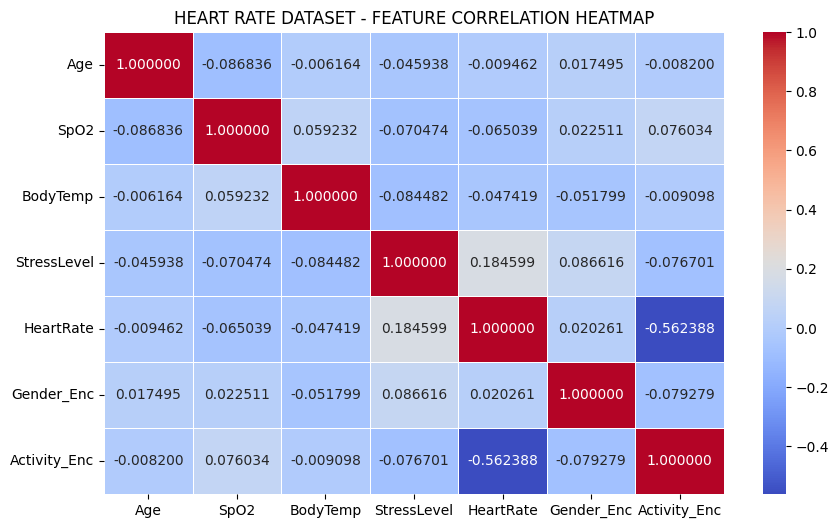

In [ ]:
plt.figure(figsize=(10,6))
# numeric columns mattum eduthu correlation pakkoom
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot = True, fmt = "2f", cmap = "coolwarm", linewidth = 0.5)
plt.title("HEART RATE DATASET - FEATURE CORRELATION HEATMAP")
plt.show()